Installing libraries.

In [ ]:
pip install faiss-gpu

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 135.3/135.3 MB 7.1 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 581.2/581.2 MB 2.0 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 3.5/3.5 MB 108.3 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 68.3/68.3 MB 14.6 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 89.6/89.6 MB 7.7 MB/s eta 0:00:00


In [ ]:
pip install langchain_community

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 2.4/2.4 MB 15.6 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 1.0/1.0 MB 69.8 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 69.4/69.4 kB 7.9 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 73.1/73.1 kB 9.5 MB/s eta 0:00:00
  Attempting uninstall: requests
    Found existing installation: requests 2.32.4
    Uninstalling requests-2.32.4:
      Successfully uninstalled requests-2.32.4
ERROR: pip's dependency resolver does not currently take into account all the packages that are installed. This behaviour is the source of the following dependency conflicts.
google-colab 1.0.0 requires requests==2.32.4, but you have requests 2.34.2 which is incompatible.


In [ ]:
pip install langchain_experimental

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 211.2/211.2 kB 3.0 MB/s eta 0:00:00


In [ ]:
pip install langchain

In [ ]:
pip install langchain_core

In [ ]:
pip install langchain-classic

In [ ]:
pip install pypdf

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 395.5/395.5 kB 4.5 MB/s eta 0:00:00


Importing libraries.

In [ ]:
import os
import time
from langchain_community.document_loaders import PyPDFLoader
from langchain_community.document_loaders import PyPDFDirectoryLoader
from langchain_text_splitters import RecursiveCharacterTextSplitter
from langchain_community.vectorstores import FAISS



from langchain_experimental.graph_transformers import LLMGraphTransformer
from langchain_classic.chains import create_retrieval_chain
from langchain_classic.chains.combine_documents import create_stuff_documents_chain
from langchain_core.prompts import ChatPromptTemplate
from langchain_classic.chains import RetrievalQA


In [ ]:
import os
import re
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import faiss

from sentence_transformers import SentenceTransformer
from sklearn.manifold import TSNE
from sklearn.metrics.pairwise import cosine_similarity

# Set publication-ready visual styling
sns.set_theme(style="whitegrid", palette="muted")
plt.rcParams.update({'font.sans-serif': 'DejaVu Sans', 'font.size': 10})

Connecting to Google Drive.

In [ ]:
from google.colab import drive
drive.mount('/content/drive')

Mounted at /content/drive


Getting PDF files in the directory.

In [ ]:
pdf_loader = PyPDFDirectoryLoader('/content/drive/My Drive/School/RAG data')

In [ ]:
pdf_docs = pdf_loader.load()

Chunks of the documents.

In [ ]:
# Split into manageable chunks
text_splitter = RecursiveCharacterTextSplitter(chunk_size=1000, chunk_overlap=200)
splits = text_splitter.split_documents(pdf_docs)
print(f"Generated {len(splits)} chunks.")

Generated 1312 chunks.


In [ ]:
# ==============================================================================
# Step 1: Extract Metadata & Text Metrics from LangChain Splits
# ==============================================================================
data = []
for idx, doc in enumerate(splits):
    text = doc.page_content
    source_path = doc.metadata.get('source', 'Unknown')
    page_num = doc.metadata.get('page', 0)

    # Classify publisher by file path / name
    if 'OPEC' in source_path.upper():
        agency = 'OPEC'
    elif 'EIA' in source_path.upper():
        agency = 'EIA'
    else:
        agency = 'Other'

    # Heuristic for table content vs narrative text
    # Checks for dense numbers/symbols typical of oil balance sheets
    digit_ratio = sum(c.isdigit() for c in text) / max(len(text), 1)
    content_type = 'Table / Data Sheet' if digit_ratio > 0.15 else 'Narrative Prose'

    # Token count estimation (rough word/subword count)
    word_count = len(text.split())
    char_count = len(text)

    data.append({
        'doc_id': idx,
        'source_file': os.path.basename(source_path),
        'agency': agency,
        'page': page_num,
        'char_count': char_count,
        'word_count': word_count,
        'digit_ratio': digit_ratio,
        'content_type': content_type,
        'text': text
    })

df_meta = pd.DataFrame(data)

In [ ]:
df_meta

,doc_id,source_file,agency,page,char_count,word_count,digit_ratio,content_type,text
0,0,annual-report-2025.pdf,Other,1,65,8,0.000000,Narrative Prose,Avaliable \nonline now:\nDownload\nthe app:\nw...
1,1,annual-report-2025.pdf,Other,2,696,91,0.053161,Narrative Prose,Organization of the Petroleum Exporting Countr...
2,2,annual-report-2025.pdf,Other,3,155,23,0.051613,Narrative Prose,05\n07\nForeword from the \nSecretary General\...
3,3,annual-report-2025.pdf,Other,4,114,16,0.070175,Narrative Prose,33\n39\nCommunication: \nEngaging the World\nL...
4,4,annual-report-2025.pdf,Other,6,963,153,0.005192,Narrative Prose,5\nForeword from the Secretary General\nHaitha...
...,...,...,...,...,...,...,...,...,...
1307,1307,1-s2.0-S0360544221006526-main.pdf,Other,14,974,154,0.090349,Narrative Prose,Forecasting crude oil price: does exist an opt...
1308,1308,1-s2.0-S0360544221006526-main.pdf,Other,14,953,155,0.094439,Narrative Prose,prices by utilizing the intelligent model sear...
1309,1309,1-s2.0-S0360544221006526-main.pdf,Other,14,961,159,0.083247,Narrative Prose,forecast global oil consumption. Grey Systems ...
1310,1310,1-s2.0-S0360544221006526-main.pdf,Other,14,960,139,0.092708,Narrative Prose,forecasting method based on the integration of...


In [ ]:
# ==============================================================================
# Step 2: Embed Chunks & Populate FAISS Vector Store
# ==============================================================================
# Load standard embedding model (or swap with HuggingFace/OpenAI)
embedder = SentenceTransformer('all-MiniLM-L6-v2')
texts = df_meta['text'].tolist()

modules.json:   0%|          | 0.00/349 [00:00<?, ?B/s]

config_sentence_transformers.json:   0%|          | 0.00/116 [00:00<?, ?B/s]

README.md:   0%|          | 0.00/10.5k [00:00<?, ?B/s]

sentence_bert_config.json:   0%|          | 0.00/53.0 [00:00<?, ?B/s]

config.json:   0%|          | 0.00/612 [00:00<?, ?B/s]

...

tokenizer_config.json:   0%|          | 0.00/350 [00:00<?, ?B/s]

vocab.txt:   0%|          | 0.00/232k [00:00<?, ?B/s]

tokenizer.json:   0%|          | 0.00/466k [00:00<?, ?B/s]

special_tokens_map.json:   0%|          | 0.00/112 [00:00<?, ?B/s]

config.json:   0%|          | 0.00/190 [00:00<?, ?B/s]

In [ ]:
# Generate and L2-normalize embeddings for cosine similarity via IndexFlatIP
embeddings = embedder.encode(texts, show_progress_bar=True, convert_to_numpy=True)
faiss.normalize_L2(embeddings)

Batches:   0%|          | 0/41 [00:00<?, ?it/s]

In [ ]:
dim = embeddings.shape[1]
faiss_index = faiss.IndexFlatIP(dim)
faiss_index.add(embeddings)

df_meta['embedding_idx'] = list(range(len(embeddings)))

Chunk Length Distribution (Word Count)

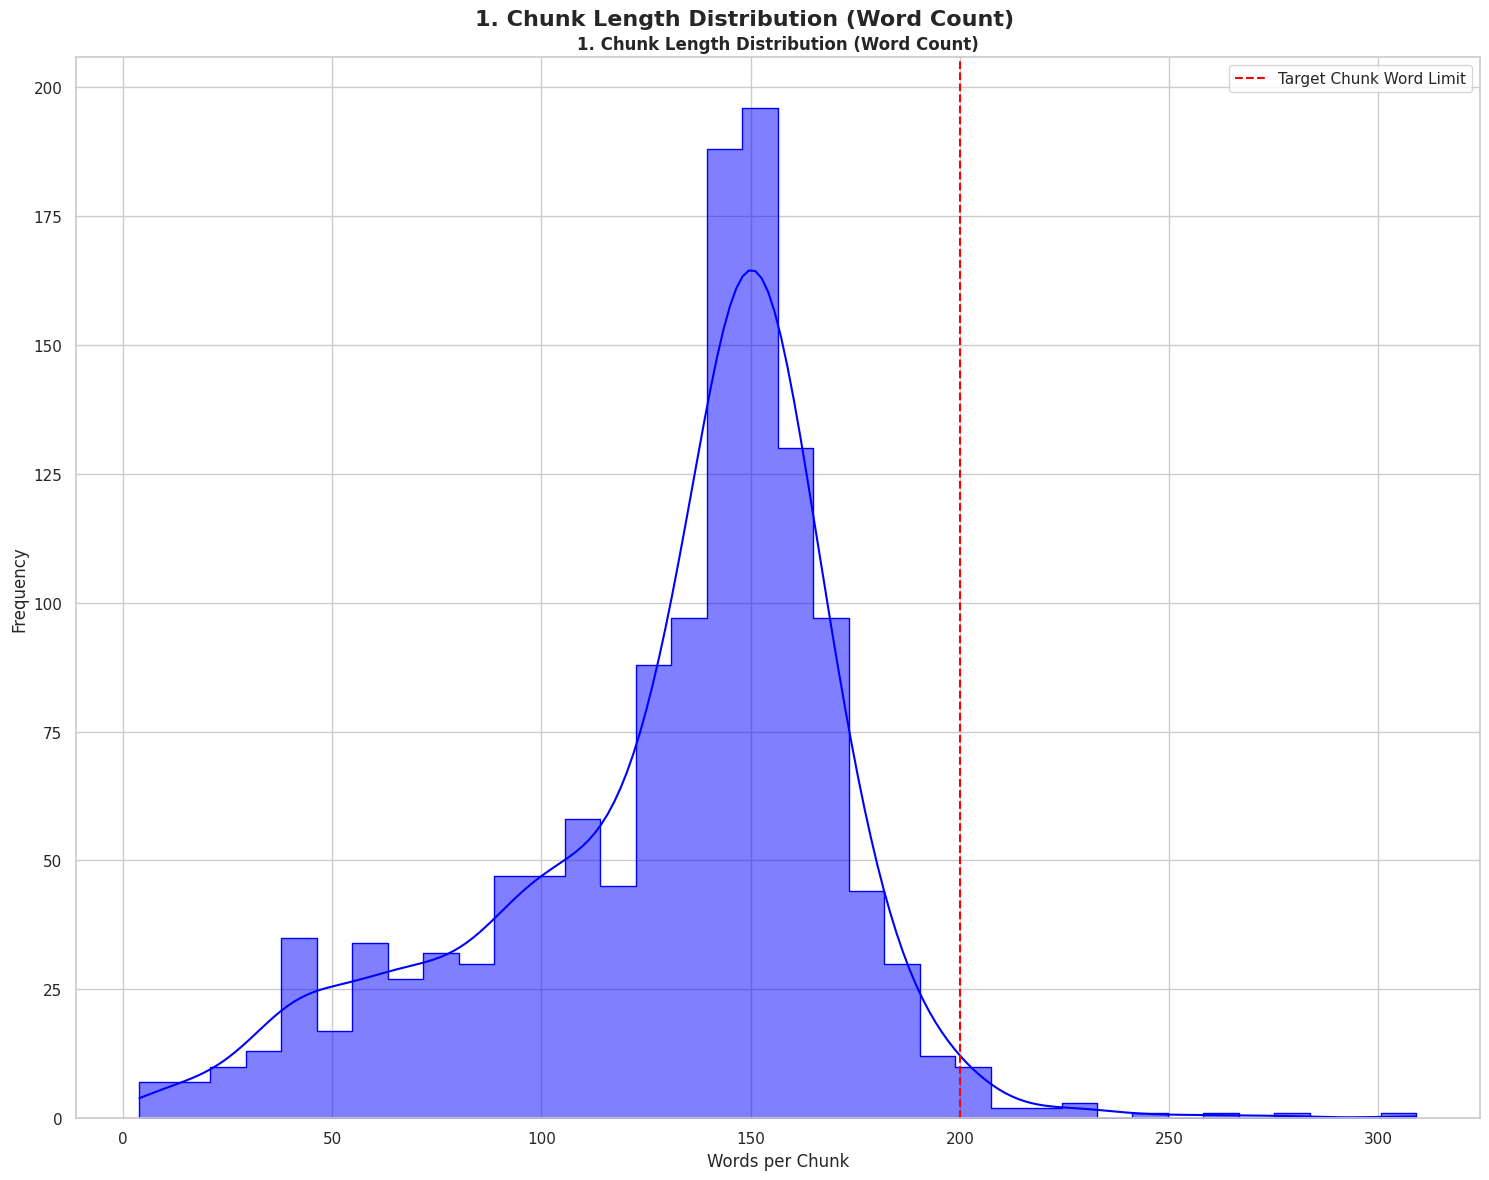

In [ ]:
# ==============================================================================
# Step 3: Run EDA Dashboard Visualizations
# ==============================================================================
fig, axes = plt.subplots(1, 1, figsize=(15, 12))
fig.suptitle("1. Chunk Length Distribution (Word Count)", fontsize=16, fontweight='bold', y=0.98)

# Chart 1: Split Character/Word Count Geometry
sns.histplot(
    data=df_meta, x='word_count', hue='agency', kde=True,
    ax=axes, palette={'OPEC': '#1f77b4', 'EIA': '#ff7f0e','Other':'#0000FF'}, alpha=0.5, element="step"
)
axes.axvline(200, color='red', linestyle='--', label='Target Chunk Word Limit')
axes.set_title("1. Chunk Length Distribution (Word Count)", fontweight='bold')
axes.set_xlabel("Words per Chunk")
axes.set_ylabel("Frequency")
axes.legend()

plt.tight_layout()
plt.savefig("1. Chunk Length Distribution (Word Count).png", dpi=300, bbox_inches="tight")
plt.show()

Vector Space Topology by Agency & Content Type

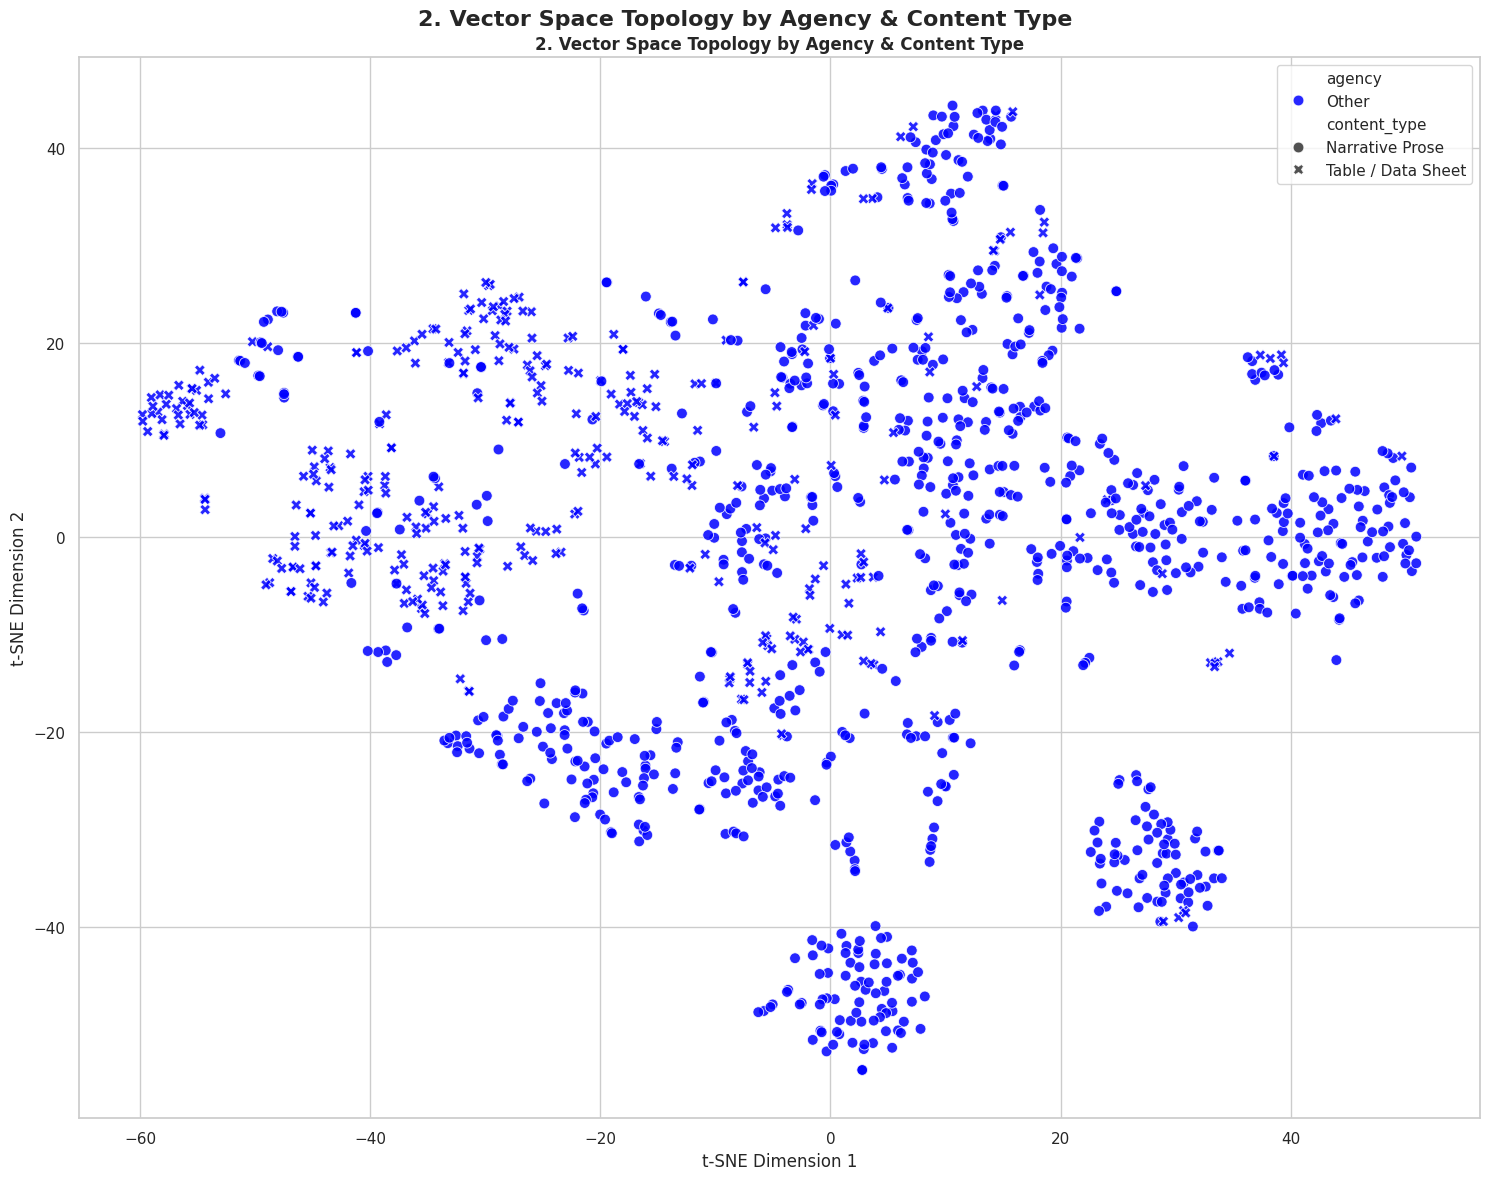

In [ ]:
fig, axes = plt.subplots(1, 1, figsize=(15, 12))
fig.suptitle("2. Vector Space Topology by Agency & Content Type", fontsize=16, fontweight='bold', y=0.98)

# Chart 2: Embedding Topological Space (t-SNE)
tsne = TSNE(n_components=2, perplexity=min(30, len(embeddings)-1), random_state=42)
embeddings_2d = tsne.fit_transform(embeddings)
df_meta['tsne_x'] = embeddings_2d[:, 0]
df_meta['tsne_y'] = embeddings_2d[:, 1]

sns.scatterplot(
    data=df_meta, x='tsne_x', y='tsne_y', hue='agency', style='content_type',
    ax=axes, palette={'OPEC': '#1f77b4', 'EIA': '#ff7f0e','Other':'#0000FF'}, s=60, alpha=0.85
)
axes.set_title("2. Vector Space Topology by Agency & Content Type", fontweight='bold')
axes.set_xlabel("t-SNE Dimension 1")
axes.set_ylabel("t-SNE Dimension 2")

plt.tight_layout()
plt.savefig("2. Vector Space Topology by Agency & Content Type.png", dpi=300, bbox_inches="tight")
plt.show()

Global Vector Anisotropy (Pairwise Cosinse Sim)

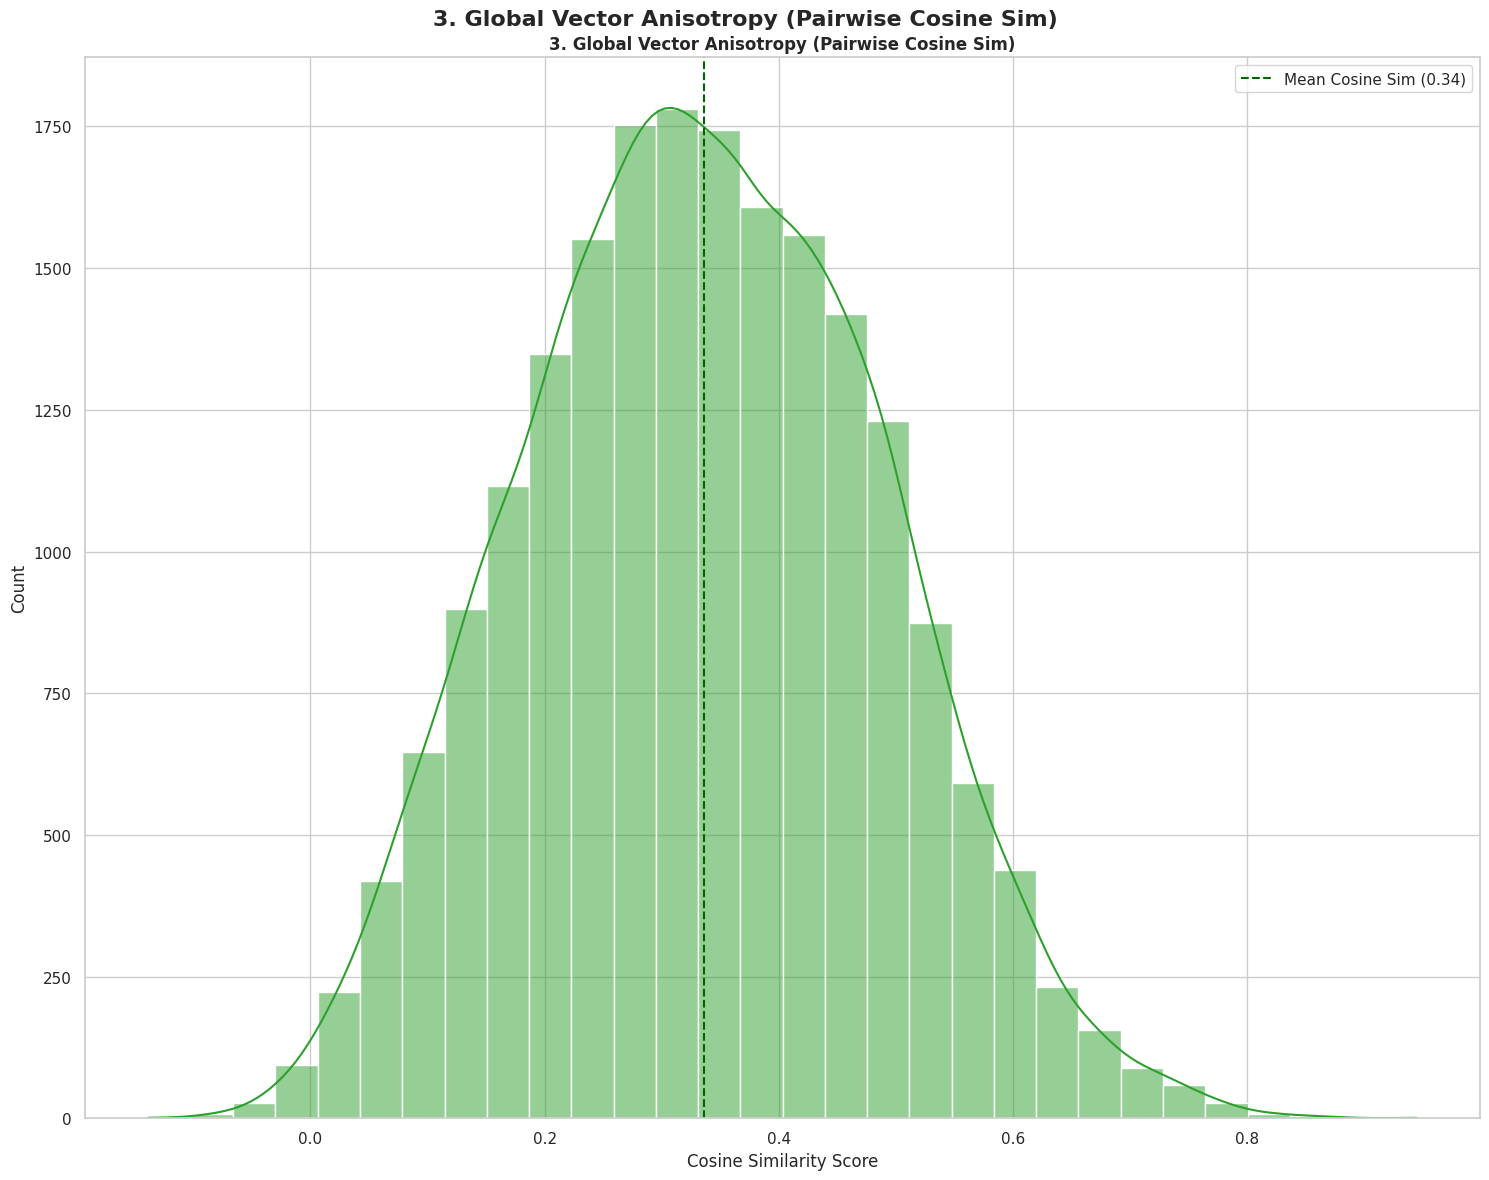

In [ ]:
fig, axes = plt.subplots(1, 1, figsize=(15, 12))
fig.suptitle("3. Global Vector Anisotropy (Pairwise Cosine Sim)", fontsize=16, fontweight='bold', y=0.98)

# Chart 3: Vector Anisotropy (Pairwise Cosine Similarity)
sample_size = min(200, len(embeddings))
sample_idx = np.random.choice(len(embeddings), size=sample_size, replace=False)
sample_embeds = embeddings[sample_idx]

cos_sim = cosine_similarity(sample_embeds)
upper_tri = cos_sim[np.triu_indices_from(cos_sim, k=1)]

sns.histplot(upper_tri, kde=True, ax=axes, color='#2ca02c', bins=30)
axes.axvline(np.mean(upper_tri), color='darkgreen', linestyle='--',
                   label=f'Mean Cosine Sim ({np.mean(upper_tri):.2f})')
axes.set_title("3. Global Vector Anisotropy (Pairwise Cosine Sim)", fontweight='bold')
axes.set_xlabel("Cosine Similarity Score")
axes.legend()

plt.tight_layout()
plt.savefig("3. Global Vector Anisotropy (Pairwise Cosine Sim).png", dpi=300, bbox_inches="tight")
plt.show()

Digit Denisyt Ratio (Numerical/Table Content Detection)

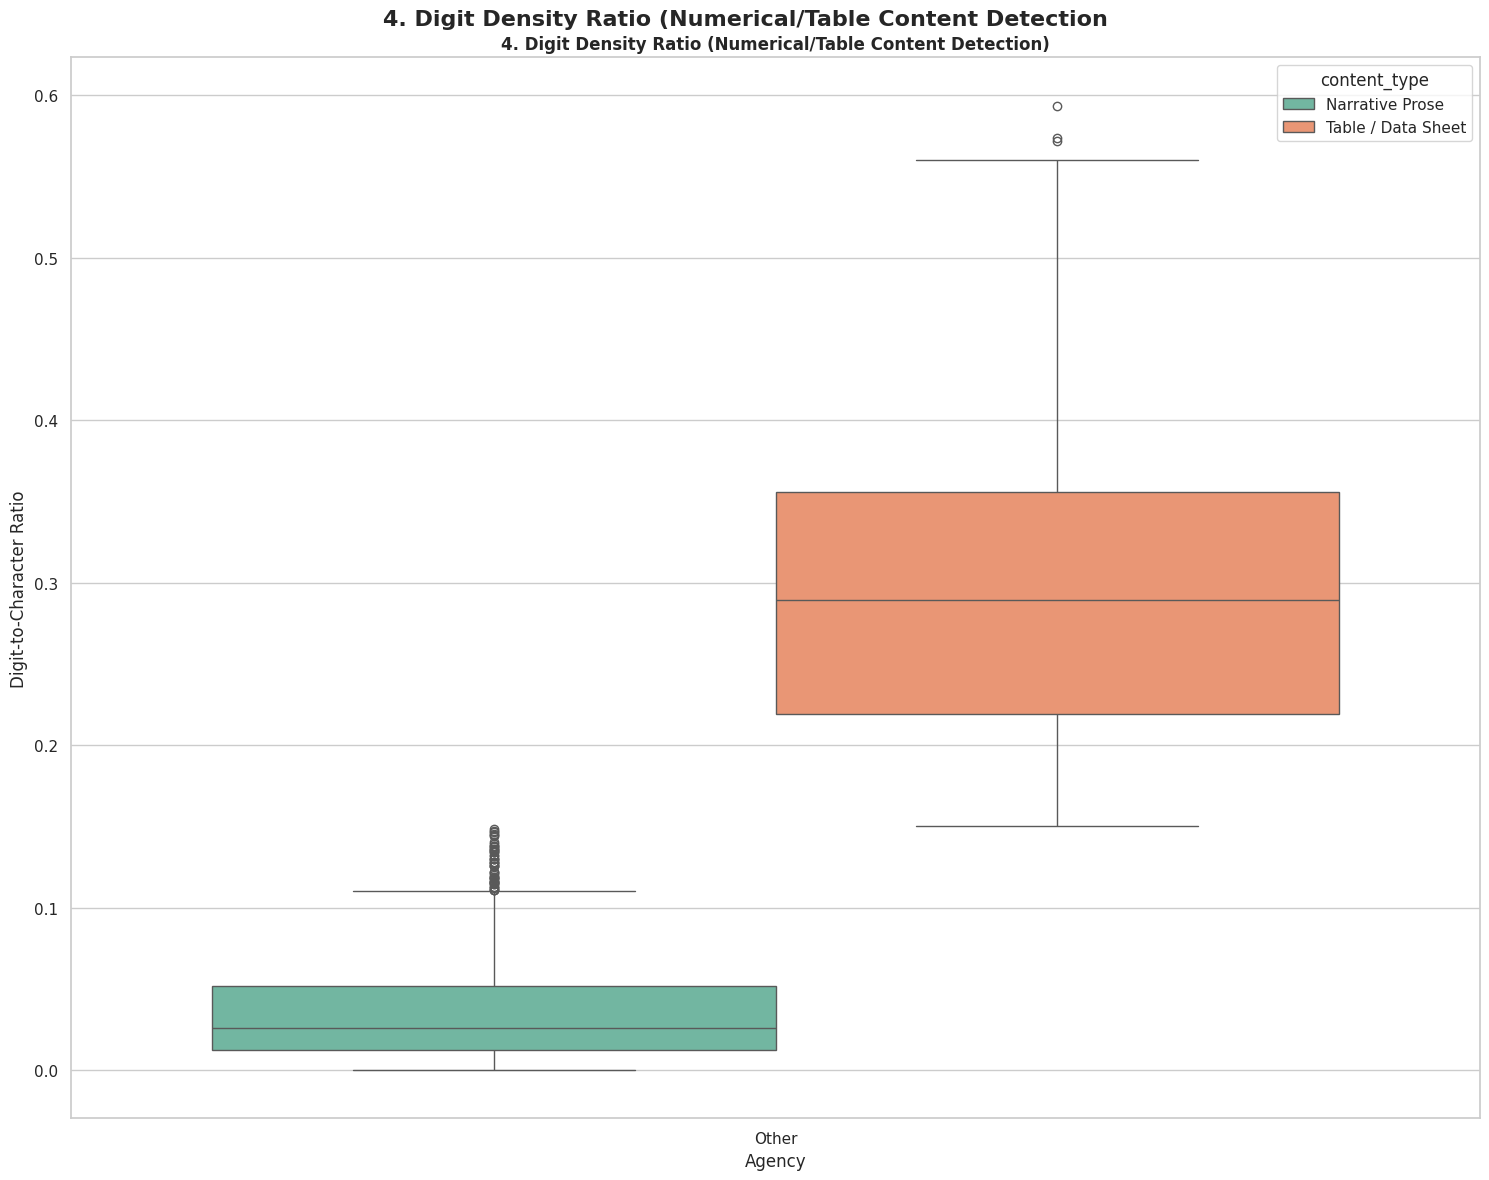

In [ ]:
fig, axes = plt.subplots(1, 1, figsize=(15, 12))
fig.suptitle("4. Digit Density Ratio (Numerical/Table Content Detection", fontsize=16, fontweight='bold', y=0.98)

# Chart 4: Table Density vs Narrative Distribution
sns.boxplot(
    data=df_meta, x='agency', y='digit_ratio', hue='content_type',
    ax=axes, palette='Set2'
)
axes.set_title("4. Digit Density Ratio (Numerical/Table Content Detection)", fontweight='bold')
axes.set_xlabel("Agency")
axes.set_ylabel("Digit-to-Character Ratio")

plt.tight_layout()
plt.tight_layout()
plt.savefig("4. Digit Density Ratio Numerical Table Content Detection.png", dpi=300, bbox_inches="tight")
plt.show()